# **Exploratory Data Analysis (EDA) with Pandas in Banking**


The purpose of this project is to master the exploratory data analysis (EDA) in banking with Pandas framework.

Goals of the Project:

1.  Explore a banking dataset with Pandas framework.
2.  Build pivot tables.
3.  Visualize the dataset with various plot types.


## Outline


*   Materials and methods
*   General part
    *   Libraries import
    *   Dataset exploration (including data quality checks)
    *   Pivot tables
    *   Visualization in Pandas
    *   Segment analysis
    *   Insight charts
*   Tasks
*   Conclusions and recommendations

***


## Materials and methods


The data that we are going to use for this is a subset of an open source Bank Marketing Data Set from the UCI ML repository: https://archive.ics.uci.edu/ml/citation_policy.html.

> This dataset is publicly available for research. The details are described in \[Moro et al., 2014].

During the work, the task of preliminary analysis of a positive response (term deposit) to direct calls from a bank is to solve. In essence, the task is a matter of bank scoring, i.e. according to the characteristics of a client (potential client), their behavior is predicted (loan default, a wish to make a deposit, etc.).

In this project, we will try to give answers to a set of questions that may be relevant when analyzing banking data:

1.  What is the share of clients attracted in our source data?
2.  What are the mean values of numerical features among the attracted clients?
3.  What is the average call duration for the attracted clients?
4.  What is the average age among the attracted and unmarried clients?
5.  What is the average age and call duration for different types of client employment?
6.  Does the data have quality problems (duplicates, `unknown` values, special codes)?
7.  How do the attracted clients differ from the clients who refused?
8.  Which client segments (job, education, age, contact type, month of contact, previous outcome) have the highest subscription rate?
9.  Do repeated calls to the same client increase the chance of a deposit?
10. What should the bank change in its next marketing campaign?

In addition, we will make a visual analysis in order to plan marketing banking campaigns more effectively.

*Note: the structure of the first part of this notebook follows a guided IBM Skills Network lab. The data quality checks, segment analysis, insight charts and the conclusions are my own extension.*

## Libraries import


The dataset can be downloaded from the UCI repository (https://archive.ics.uci.edu/dataset/222/bank+marketing). Unzip it and keep the folder `bank-additional`, which contains the file `bank-additional-full.csv`, in the same folder as this notebook.

Importing the libraries necessary for this project. We can add some aliases to make the libraries easier to use in our code and set a default figure size for further plots.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 6)

import warnings
warnings.filterwarnings('ignore')

Further specify the value of the `precision` parameter equal to 2 to display two decimal signs (instead of 6 as default).


In [2]:
pd.set_option("display.precision", 2)
pd.options.display.float_format = '{:.2f}'.format

## Dataset exploration


In this section we will explore the sourse dataset.


Let's read the data and look at the first 5 rows using the `head` method. The number of the output rows from the dataset is determined by the `head` method parameter.


In [3]:
df = pd.read_csv('bank-additional/bank-additional-full.csv', sep = ';')
df.head(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,no


### Let's look at the dataset size, feature names and their types


In [4]:
df.shape
df.tail(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,-1.10,94.77,-50.80,1.03,4963.60,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,-1.10,94.77,-50.80,1.03,4963.60,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,-1.10,94.77,-50.80,1.03,4963.60,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,-1.10,94.77,-50.80,1.03,4963.60,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,239,3,999,1,failure,-1.10,94.77,-50.80,1.03,4963.60,no


The dataset contains 41188 objects (rows), for each of which 21 features are set (columns), including 1 target feature (`y`).


### Attributing information


Output the column (feature) names:


In [5]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

Input features (column names):

1.  `age` - client's age in years (numeric)
2.  `job` - type of job (categorical: `admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown`)
3.  `marital` - marital status (categorical: `divorced`, `married`, `single`, `unknown`)
4.  `education` - client's education (categorical: `basic.4y`, `basic.6y`, `basic.9y`, `high.school`, `illiterate`, `professional.course`, `university.degree`, `unknown`)
5.  `default` - has credit in default? (categorical: `no`, `yes`, `unknown`)
6.  `housing` - has housing loan? (categorical: `no`, `yes`, `unknown`)
7.  `loan` - has personal loan? (categorical: `no`, `yes`, `unknown`)
8.  `contact` - contact communication type (categorical: `cellular`, `telephone`)
9.  `month` - last contact month of the year (categorical: `jan`, `feb`, `mar`, ..., `nov`, `dec`)
10. `day_of_week` - last contact day of the week (categorical: `mon`, `tue`, `wed`, `thu`, `fri`)
11. `duration` - last contact duration, in seconds (numeric).
12. `campaign` - number of contacts performed and for this client during this campaign (numeric, includes the last contact)
13. `pdays` - number of days that have passed after the client was last contacted from the previous campaign (numeric; 999 means the client has not been previously contacted)
14. `previous` - number of contacts performed for this client before this campaign (numeric)
15. `poutcome` - outcome of the previous marketing campaign (categorical: `failure`, `nonexistent`, `success`)
16. `emp.var.rate` - employment variation rate, quarterly indicator (numeric)
17. `cons.price.idx` - consumer price index, monthly indicator (numeric)
18. `cons.conf.idx` - consumer confidence index, monthly indicator (numeric)
19. `euribor3m` - euribor 3 month rate, daily indicator (numeric)
20. `nr.employed` - number of employees, quarterly indicator (numeric)

Output feature (desired target):

21. `y` - has the client subscribed a term deposit? (binary: `yes`,`no`)


To see the general information on all the DataFrame features (columns), we use the **`info`** method:


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

As we can see, the dataset is full, no pass (`non-null`), so there is no need to fill the gaps. The dataset contains 5 integer (`int64`), 5 real (`float64`) and 11 categorical and binary (`object`) features.


Method **`describe`** shows the main statistical characteristics of the dataset for each numerical feature (`int64` and `float64` types): the existing values number, mean, standard deviation, range, min & max, 0.25, 0.5 and 0.75 quartiles.


In [7]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,258.29,2.57,962.48,0.17,0.08,93.58,-40.50,3.62,5167.04
std,10.42,259.28,2.77,186.91,0.49,1.57,0.58,4.63,1.73,72.25
min,17.00,0.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60
25%,32.00,102.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10
50%,38.00,180.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,319.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,98.00,4918.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10


To see the statistics on non-numeric features, we need to explicitly specify the feature types by the `include` parameter. We can also set `include = all` to output statistics on all the existing features.


In [8]:
df.describe(include = ["object"])

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


The result shows that the average client refers to administrative staff (`job = admin.`), is married (`marital = married`) and has a university degree (`education = university.degree`).


### Data quality checks

Before the analysis, we check the quality of the data. First, let's see whether there are duplicated rows.

In [9]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 12


The dataset contains only 12 duplicated rows (0.03% of the data), so they do not affect the results and we keep them.

The `info` method showed no null values, but the missing information in this dataset is coded as the text `unknown`. Let's count these values in every column.

In [10]:
unk = (df == 'unknown').sum()
print(unk[unk > 0].sort_values(ascending=False))
print((unk[unk > 0] / len(df) * 100).round(1).astype(str) + '%')

default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64
job           0.8%
marital       0.2%
education     4.2%
default      20.9%
housing       2.4%
loan          2.4%
dtype: object


As we can see, `default` has the most unknown values (8597 rows, about 21%), followed by `education` (4.2%) and `housing` and `loan` (2.4% each). Instead of dropping these rows we keep `unknown` as a separate category, because it can carry information of its own.

Two features contain special values. `pdays = 999` means that the client was not contacted in a previous campaign, and `duration = 0` is a call that always ends with `no` (as stated in the dataset description). Let's check how often they occur.

In [11]:
print('Never contacted before:', '{:.1%}'.format((df['pdays'] == 999).mean()))
print('Calls with duration 0  :', (df['duration'] == 0).sum())

Never contacted before: 96.3%
Calls with duration 0  : 4


So, 96.3% of the clients were never contacted before (`pdays = 999`). This value is a code and not a real number of days, so it should not be used in averages. Only 4 calls have `duration = 0`. Also, `duration` is known only after the call, so we use it to describe the data, but not to decide whom to call.

For categorical (type `object`) and boolean (type `bool`) features you can use the **`value_counts`** method. Let's look at the target feature (`y`) distribution:


In [12]:
df["y"].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

4640 clients (11.3%) of 41188 issued a term deposit, the value of the variable `y` equals `yes`.

Let's look at the client distribution by the variable `marital`. Specify the value of the `normalize = True` parameter to view relative frequencies, but not absolute.

In [13]:
df["marital"].value_counts(normalize = True)

marital
married    0.61
single     0.28
divorced   0.11
unknown    0.00
Name: proportion, dtype: float64

As we can see, 61% (0.61) of clients are married, which must be taken into account when planning marketing campaigns to manage deposit operations.


### Sorting


A `DataFrame` can be sorted by a few feature values. In our case, for example, by `duration` (`ascending = False` for sorting in descending order):


In [14]:
df.sort_values(by = "duration", ascending = False).head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
24091,33,technician,single,professional.course,no,yes,no,telephone,nov,mon,4918,1,999,0,nonexistent,-0.10,93.20,-42.00,4.41,5195.80,no
22192,52,blue-collar,married,basic.4y,no,no,no,telephone,aug,thu,4199,3,999,0,nonexistent,1.40,93.44,-36.10,4.96,5228.10,yes
40537,27,admin.,single,high.school,no,no,no,telephone,aug,fri,3785,1,999,0,nonexistent,-1.70,94.03,-38.30,0.89,4991.60,no
13820,31,technician,married,professional.course,no,no,no,cellular,jul,thu,3643,1,999,0,nonexistent,1.40,93.92,-42.70,4.96,5228.10,yes
7727,37,unemployed,married,professional.course,no,yes,no,telephone,may,fri,3631,2,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,yes


The sorting results show that the longest calls exceed one hour, as the value `duration` is more than 3600 seconds or 1 hour. At the same time, it usually was on Mondays and Thursdays (`day_of_week`) and, especially, in November and August (`month`).


Sort by the column group:


In [15]:
df.sort_values(by = ["age", "duration"], ascending = [True, False]).head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
38274,17,student,single,unknown,no,no,yes,cellular,oct,tue,896,1,2,2,success,-3.40,92.43,-26.90,0.74,5017.50,yes
37579,17,student,single,basic.9y,no,unknown,unknown,cellular,aug,fri,498,2,999,1,failure,-2.90,92.20,-31.40,0.87,5076.20,yes
37140,17,student,single,unknown,no,yes,no,cellular,aug,wed,432,3,4,2,success,-2.90,92.20,-31.40,0.88,5076.20,no
37539,17,student,single,basic.9y,no,yes,no,cellular,aug,fri,182,2,999,2,failure,-2.90,92.20,-31.40,0.87,5076.20,no
37558,17,student,single,basic.9y,no,yes,no,cellular,aug,fri,92,3,4,2,success,-2.90,92.20,-31.40,0.87,5076.20,no


We see that the youngest customers are at the `age` of 17, and the call `duration` exceeded 3 minutes only for three clients, which indicates the ineffectiveness of long-term interaction with such clients.


### Application of functions: `apply`, `map` etc.


**Apply the function to each column:**


In [16]:
df.apply(np.max)

age                      98
job                 unknown
marital             unknown
education           unknown
default                 yes
housing                 yes
loan                    yes
contact           telephone
month                   sep
day_of_week             wed
duration               4918
campaign                 56
pdays                   999
previous                  7
poutcome            success
emp.var.rate           1.40
cons.price.idx        94.77
cons.conf.idx        -26.90
euribor3m              5.04
nr.employed         5228.10
y                       yes
dtype: object

The oldest client is 98 years old (`age` = 98), and the number of contacts with one of the customers reached 56 (`campaign` = 56).


**Apply the function to each column cell**


The `map` can also be used for **the values ​​replacement in a column** by passing it as an argument dictionary in form of ` {old_value: new_value}  `.

In [17]:
d = {"no": 0, "yes": 1}
df["y"] = df["y"].map(d)
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0


### Indexing and extracting data


A `DataFrame` can be indexed in many ways. In this regard, consider various ways of indexing and extracting data from the DataFrame with simple question examples.

We can use the code `dataframe ['name']` to extract a separate column. We use this to answer the question: **What is the share of clients attracted in our DataFrame?**


In [18]:
print("Share of attracted clients =", '{:.1%}'.format(df["y"].mean()))

Share of attracted clients = 11.3%


11.3% is a rather bad indicator for a bank, with such a percentage of attracted customers a business can collapse. The target is imbalanced: only 4640 of 41188 calls ended with a deposit.

Logical indexation by one column of a `DataFrame` is very convenient. It looks like this: `df [p(df['Name']]`, where`  p ` is a certain logical condition that is checked for each element of the `Name` column. The result of such an indexation is a `DataFrame` consisting only of the rows satisfying the condition `p` by the `Name` column.

We use this to answer the question: **What are the mean values ​​of numerical features among the attracted clients?**

In [19]:
df[df["y"] == 1].mean(numeric_only = True) 

age                40.91
duration          553.19
campaign            2.05
pdays             792.04
previous            0.49
emp.var.rate       -1.23
cons.price.idx     93.35
cons.conf.idx     -39.79
euribor3m           2.12
nr.employed      5095.12
y                   1.00
dtype: float64

Thus, the average age of the attracted clients is about 40 (`age` = 40.91), and 2 calls were required to attract them (`campaign` = 2.05).


The averages of the attracted clients alone do not say much, so let's compare them with the clients who did **not** subscribe (`y = 0`). We group the data by `y` and take the mean of the main numerical features:

In [20]:
num_cols = ['age', 'duration', 'campaign', 'previous', 'euribor3m', 'nr.employed', 'emp.var.rate']
df.groupby('y')[num_cols].mean().round(2)

,age,duration,campaign,previous,euribor3m,nr.employed,emp.var.rate
y,,,,,,,
0,39.91,220.84,2.63,0.13,3.81,5176.17,0.25
1,40.91,553.19,2.05,0.49,2.12,5095.12,-1.23


The comparison shows that the attracted clients talked much longer (`duration` = 553 vs 221 seconds), were contacted fewer times in this campaign (`campaign` = 2.05 vs 2.63), but more times before it (`previous` = 0.49 vs 0.13). They were also reached when the euribor rate was lower (`euribor3m` = 2.12 vs 3.81) and the employment variation was lower (`emp.var.rate` = -1.23 vs 0.25). Age is almost the same in both groups (40.9 vs 39.9). Note that long calls do not cause subscriptions: the call simply lasts longer when the client is interested.

Combining two previous types of indexation, we will answer the question: **What is the average call duration for the attracted clients**?


In [21]:
acd = round(df[df["y"] == 1]["duration"].mean(), 2)
acd_in_min = acd // 60
print("Average call duration for attracted clients =", acd_in_min, "min", int(acd) % 60, "sec")

Average call duration for attracted clients = 9.0 min 13 sec


So, the average duration of a successful call is almost 553 seconds, that is, nearly 10 minutes.


**What is the average age of attracted (`y == 1`) and unmarried (`'marital' == 'single'`) clients?**


In [22]:
print("Average age of attracted clients =", int(df[(df["y"] == 1) & (df["marital"] == "single")]["age"].mean()), "years")

Average age of attracted clients = 31 years


The average age of unmarried attracted clients is 31, which should be considered when working with such clients.


If we need to get the first or last line of the DataFrame, we can use the code `df[:1]` or `df[-1:]`:


In [23]:
df[-1:]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,239,3,999,1,failure,-1.10,94.77,-50.80,1.03,4963.60,0


## Pivot tables


Suppose we want to see how observations in our sample are distributed in the context of two features - `y` and `marital`. To do this, we can build **cross tabulation** by the `crosstab` method.

In [24]:
pd.crosstab(df["y"], df["marital"])

marital,divorced,married,single,unknown
y,,,,
0,4136,22396,9948,68
1,476,2532,1620,12


The result shows that the number of attracted married clients is 2532 (`y = 1` for `married`) from the total number.


In [25]:
pd.crosstab(df["y"],
            df["marital"],
            normalize = 'index')

marital,divorced,married,single,unknown
y,,,,
0,0.11,0.61,0.27,0.00
1,0.10,0.55,0.35,0.00


We see that more than half of the clients (61%, column `married`) are married and have not issued a deposit.


In `Pandas`, **pivot tables** are implemented by the method `pivot_table` with such parameters:

*   `values` – a list of variables to calculate the necessary statistics,
*   `index` – a list of variables to group data,
*   `aggfunc` — values that we actually need to count by groups - the amount, average, maximum, minimum or something else.

Let's find the average age and the call duration for different types of client employment `job`:


In [26]:
df.pivot_table(
    ["age", "duration"],
    ["job"],
    aggfunc = "mean",
).head(10)

,age,duration
job,,
admin.,38.19,254.31
blue-collar,39.56,264.54
entrepreneur,41.72,263.27
housemaid,45.50,250.45
management,42.36,257.06
retired,62.03,273.71
self-employed,39.95,264.14
services,37.93,258.40
student,25.89,283.68


The obtained results allow us to plan marketing banking campaigns more effectively.


## Visualization in Pandas


Method **scatter_matrix** allows you to visualize the pairwise dependencies between the features (as well as the distribution of each feature on the diagonal). We will do it for numerical features.


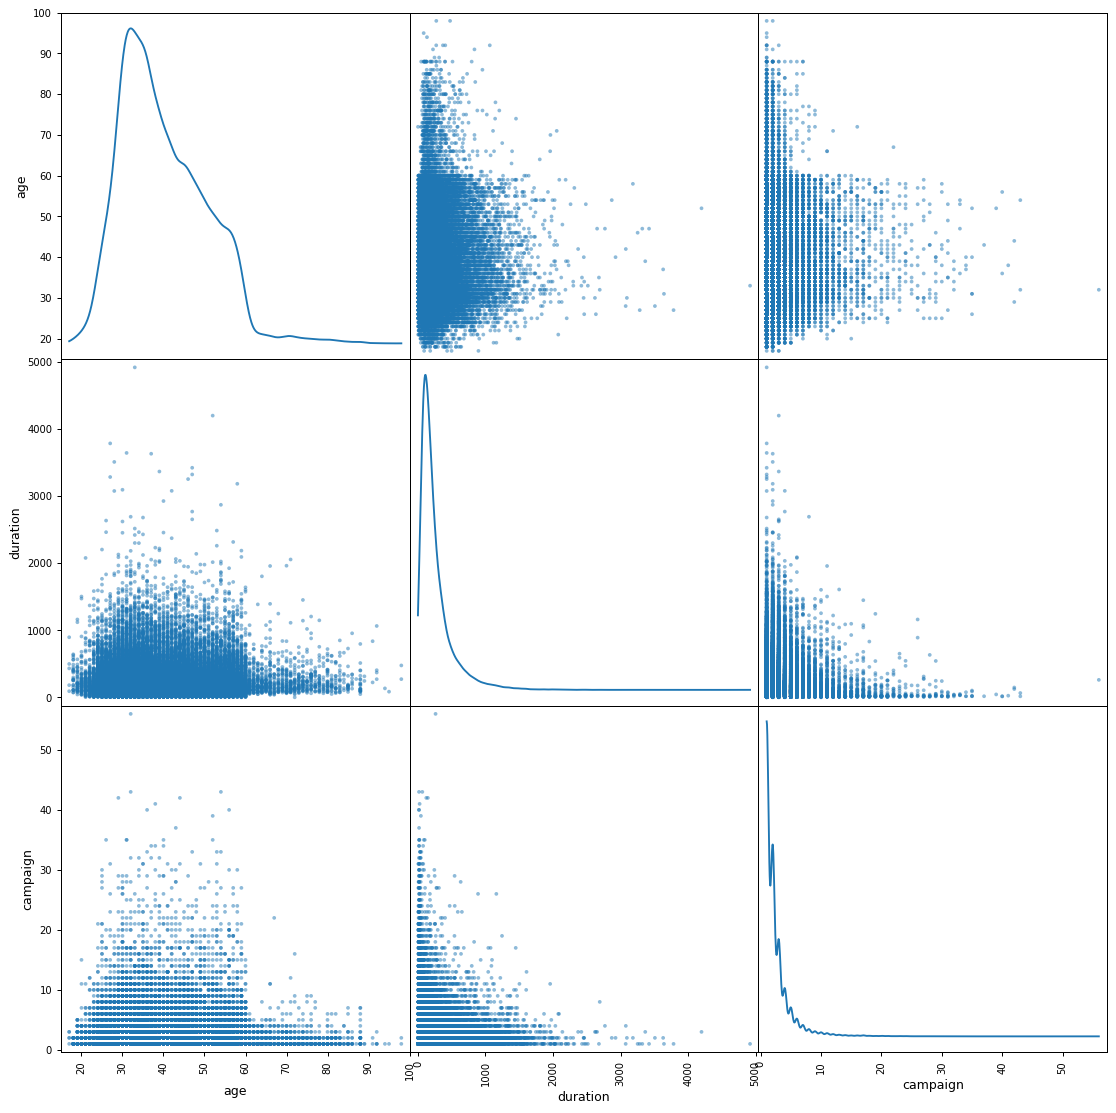

In [27]:
pd.plotting.scatter_matrix(
    df[["age", "duration", "campaign"]],
    figsize = (15, 15),
    diagonal = "kde")
plt.show()

A scatter matrix (pairs plot) compactly plots all the numeric variables we have in a dataset against each other.
The plots on the main diagonal allow you to visually define the type of data distribution: the distribution is similar to normal for age, and for a call duration and the number of contacts, the [geometric distribution](https://en.wikipedia.org/wiki/geometric_distribution?utm_medium=Exinfluencer\&utm_source=Exinfluencer\&utm_content=000026UJ\&utm_term=10006555\&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkQuickLabsEDA_Pandas_Banking_L126457256-2021-01-01) is more suitable.


**Now We will build a separate histogram for `age` feature:**


<Axes: >

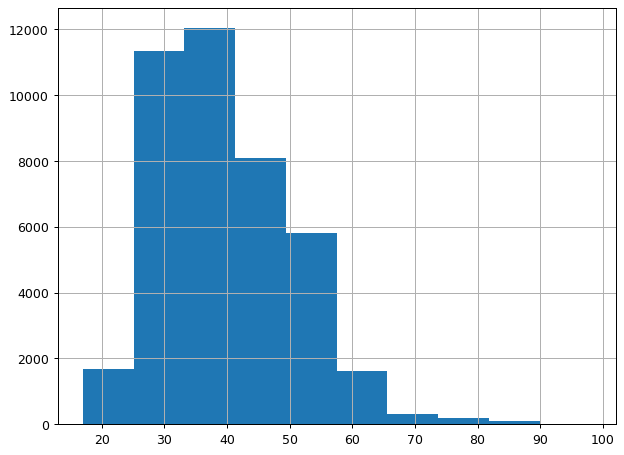

In [28]:
df["age"].hist()

The histogram shows that most of our clients are between the ages of 25 and 50, which corresponds to the actively working part of the population.


**Now we will build histogram for features all together:**


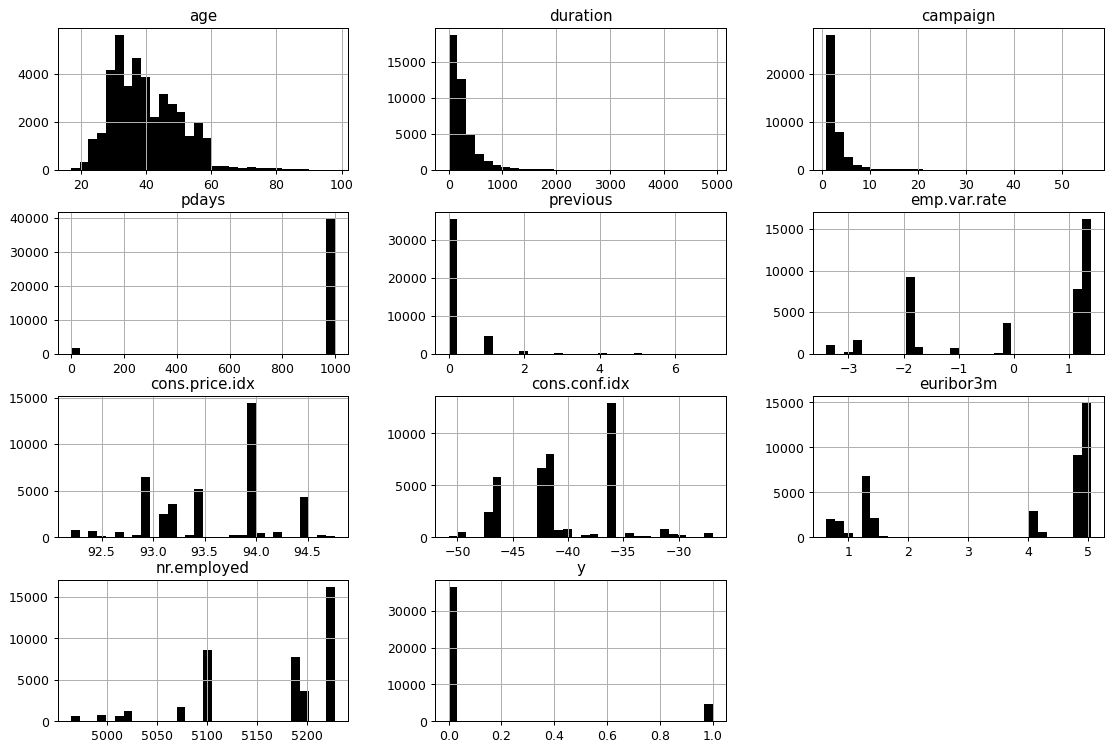

In [29]:
df.hist(color = "k",
        bins = 30,
        figsize = (15, 10))
plt.show()

A visual analysis of the histograms presented allows us to make preliminary assumptions about the variability of the source data.


Now we will use Box Plot. It will allow us to compactly visualize the main characteristics of the feature distribution (the median, lower and upper quartile, minimal and maximum, outliers).


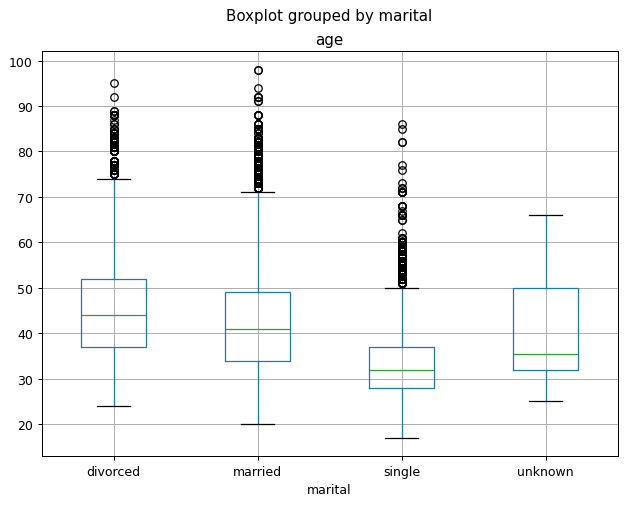

In [30]:
df.boxplot(column = "age",
           by = "marital")
plt.show()

The plot shows that unmarried people are on average younger than divorced and married ones. For the last two groups, there is an outlier zone over 70 years old, and for unmarried - over 50.


**Now we will try to do this by data grouping on other features:**

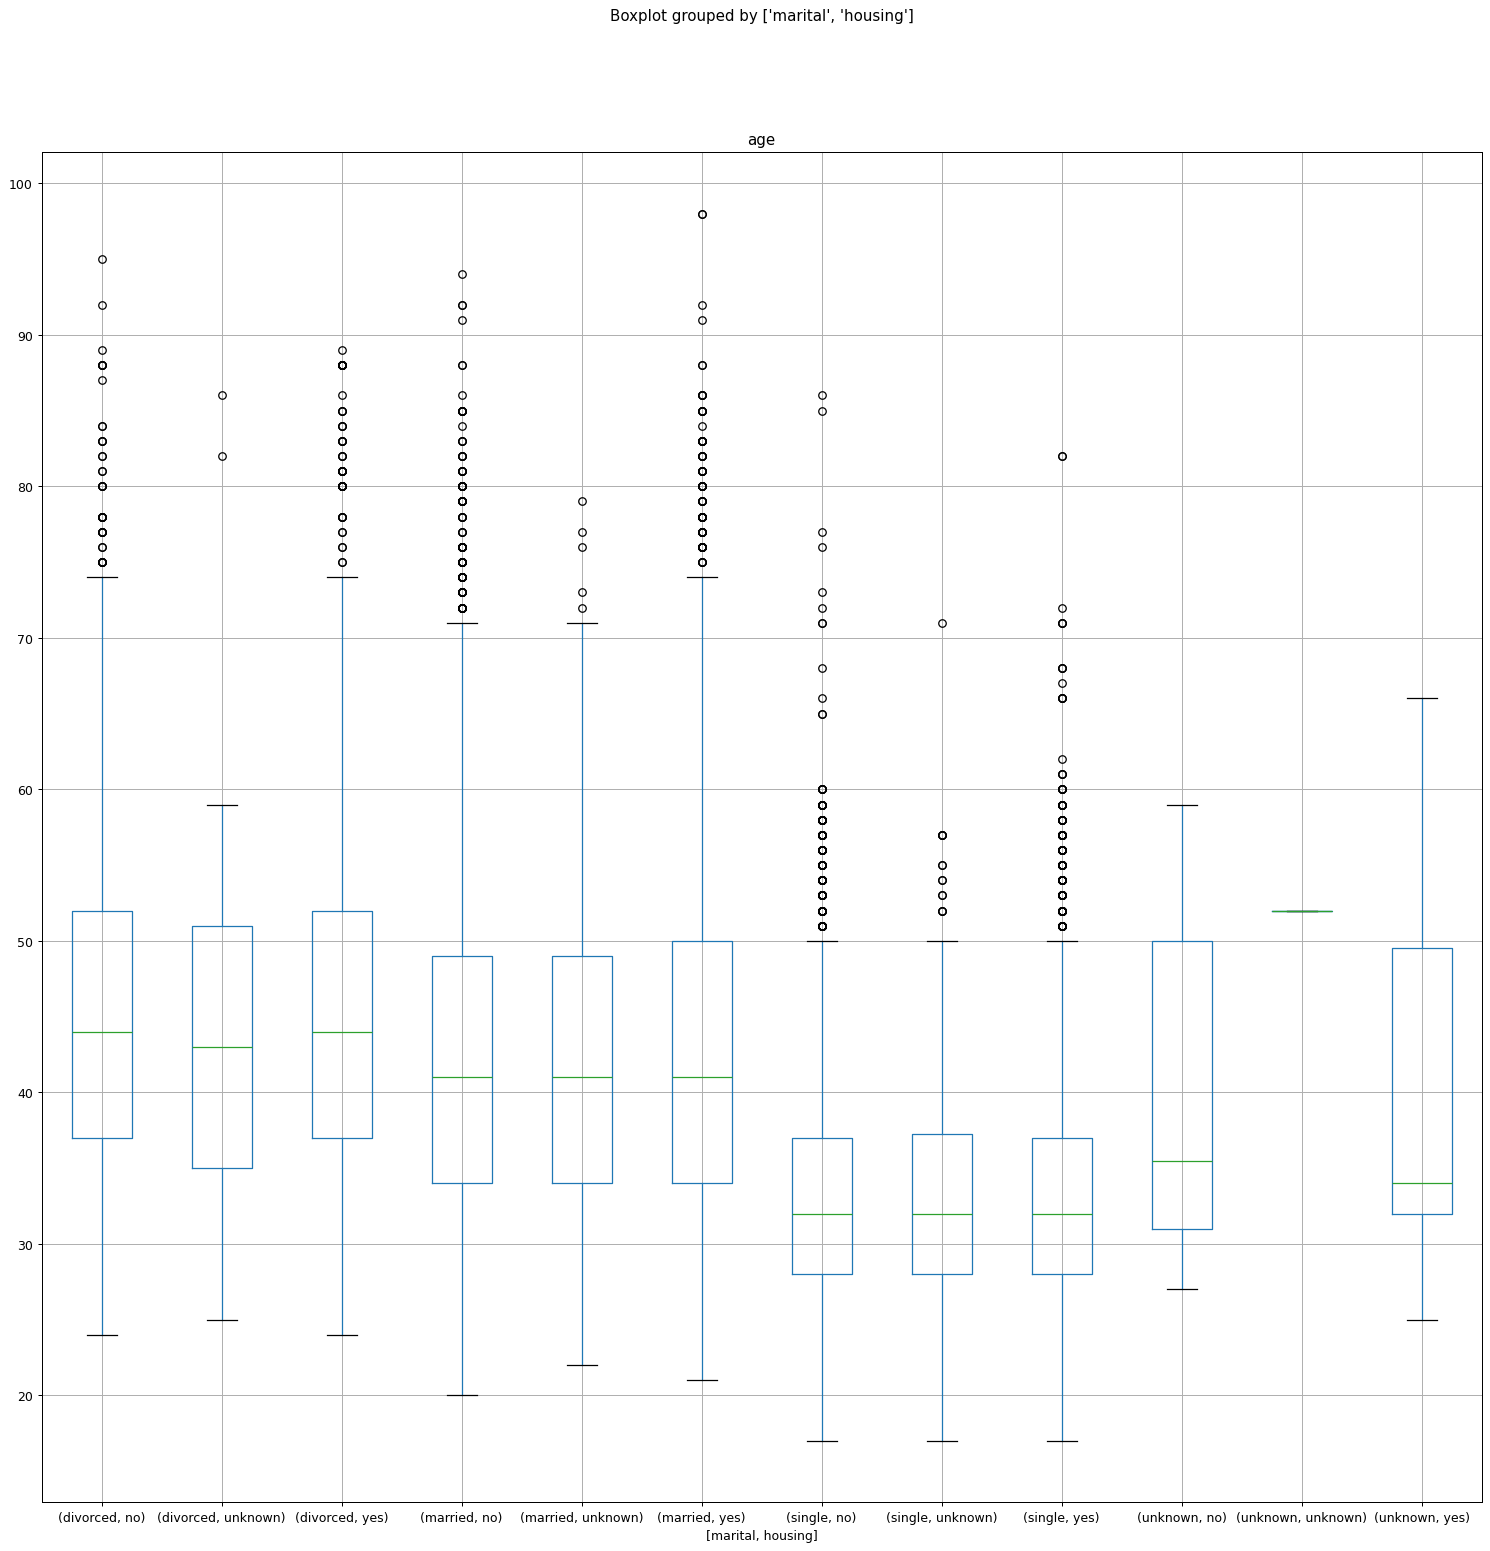

In [31]:
df.boxplot(column = "age",
           by = ["marital", "housing"],
           figsize = (20, 20))
plt.show()

As we can see, age and marital status do not have any significant influence on having a housing loan.


## Segment analysis

Counts show only whom the bank called most. To find who is **most likely** to subscribe, we need the **subscription rate** of every segment, that is the mean of `y` (since `y` is 0 or 1), together with the number of clients in the segment. Let's define a helper function and apply it to `job`:

In [32]:
def rate_by(col, top=None):
    out = (df.groupby(col, observed=True)['y']
             .agg(rate='mean', clients='count')
             .sort_values('rate', ascending=False))
    out['rate'] = (out['rate'] * 100).round(1)
    return out if top is None else out.head(top)

rate_by('job')

,rate,clients
job,,
student,31.40,875
retired,25.20,1720
unemployed,14.20,1014
admin.,13.00,10422
management,11.20,2924
unknown,11.20,330
technician,10.80,6743
self-employed,10.50,1421
housemaid,10.00,1060


Students (31.4%) and retired clients (25.2%) subscribe far more often than the others, while blue-collar (6.9%) and services (8.1%) workers subscribe least. However, the blue-collar group is more than 10 times bigger than the student group, so the bank should consider both the rate and the size of a segment.

**Subscription rate by education:**

In [33]:
rate_by('education')

,rate,clients
education,,
illiterate,22.20,18
unknown,14.50,1731
university.degree,13.70,12168
professional.course,11.30,5243
high.school,10.80,9515
basic.4y,10.20,4176
basic.6y,8.20,2292
basic.9y,7.80,6045


Clients with a university degree (13.7%) subscribe more often than clients with basic education (7.8% to 10.2%). The group `illiterate` has the highest rate (22.2%), but it contains only 18 clients, so this value is not reliable.

**By month of the last contact:**

In [34]:
rate_by('month')

,rate,clients
month,,
mar,50.50,546
dec,48.90,182
sep,44.90,570
oct,43.90,718
apr,20.50,2632
aug,10.60,6178
jun,10.50,5318
nov,10.10,4101
jul,9.00,7174


March (50.5%), December (48.9%), September (44.9%) and October (43.9%) have very high rates, but together they contain only 2016 calls. May has 13769 calls, a third of all calls, and the lowest rate (6.4%). This may also reflect which clients were called in each month, and not only the month itself.

**By contact type:**

In [35]:
rate_by('contact')

,rate,clients
contact,,
cellular,14.70,26144
telephone,5.20,15044


Cellular contact gives a rate of 14.7% against 5.2% for telephone, which is almost three times better.

**By the outcome of the previous campaign:**

In [36]:
rate_by('poutcome')

,rate,clients
poutcome,,
success,65.10,1373
failure,14.20,4252
nonexistent,8.80,35563


Clients who subscribed in a previous campaign (`success`) subscribe again in 65.1% of cases, while for new clients (`nonexistent`) the rate is only 8.8%. Thus, previous customers are the most valuable group for new campaigns.

**By age group.** We split `age` into bands with the `cut` method:

In [37]:
df['age_band'] = pd.cut(df['age'], [16, 25, 35, 45, 55, 65, 100],
                        labels=['<=25', '26-35', '36-45', '46-55', '56-65', '65+'])
rate_by('age_band').sort_index()

,rate,clients
age_band,,
<=25,20.90,1666
26-35,11.70,14847
36-45,8.50,12844
46-55,8.70,8249
56-65,15.20,2963
65+,46.80,619


The rate has a U-shape: the youngest (20.9% for 25 and younger) and the oldest (46.8% for 65+) clients subscribe most, while clients aged 36 to 55 subscribe in less than 9% of cases, although they are the biggest part of the client base.

**Do repeated calls help?** Let's look at the subscription rate by the number of contacts (`campaign`):

In [38]:
df.groupby('campaign')['y'].mean().head(10).mul(100).round(1)

campaign
1    13.00
2    11.50
3    10.70
4     9.40
5     7.50
6     7.70
7     6.00
8     4.20
9     6.00
10    5.30
Name: y, dtype: float64

The rate falls from 13% for the first contact to about 5% for the tenth, so every additional call brings less result.

**Job and contact type together** (pivot table of the subscription rate, %):

In [39]:
(df.pivot_table(values='y', index='job', columns='contact', aggfunc='mean') * 100).round(1)

contact,cellular,telephone
job,,
admin.,16.30,5.90
blue-collar,9.00,4.30
entrepreneur,10.40,5.80
housemaid,13.00,5.50
management,14.40,5.30
retired,31.60,9.20
self-employed,14.40,3.80
services,11.00,4.20
student,36.40,15.20


For every job group cellular contact works better than telephone, for example 36.4% vs 15.2% for students and 31.6% vs 9.2% for retired clients. So, the contact type is important regardless of the client's profession.

## Insight charts

Now let's show the strongest findings in charts. First, the subscription rate by job:

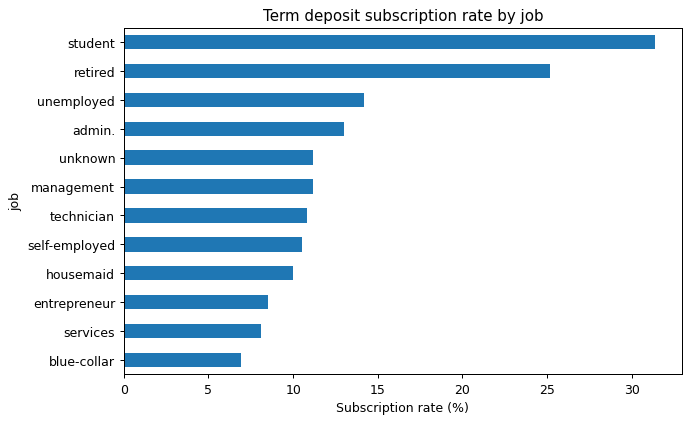

In [40]:
rate_by('job')['rate'].sort_values().plot(kind='barh', figsize=(8, 5))
plt.xlabel('Subscription rate (%)')
plt.title('Term deposit subscription rate by job')
plt.show()

The chart clearly shows that students and retired clients are far ahead of all other jobs.

The subscription rate by month:

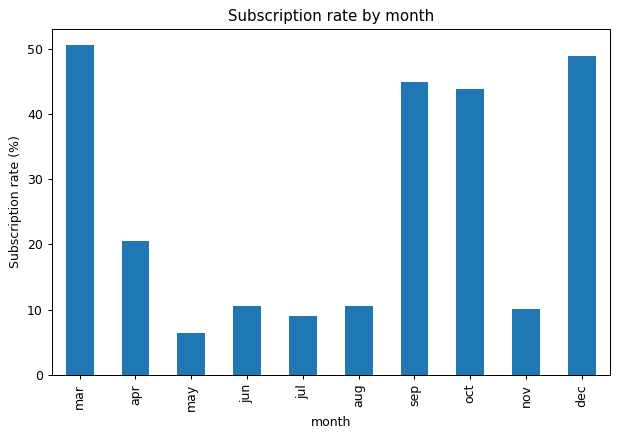

In [41]:
order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
(df.groupby('month')['y'].mean().reindex(order) * 100).plot(kind='bar', figsize=(8, 5))
plt.ylabel('Subscription rate (%)')
plt.title('Subscription rate by month')
plt.show()

March, September, October and December are far above the other months, while May to August and November stay between 6% and 11%.

The call duration for attracted and not attracted clients:

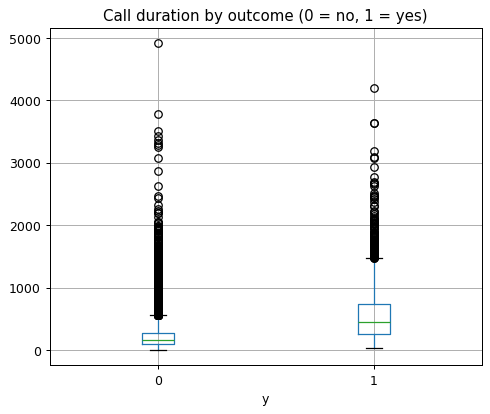

In [42]:
df.boxplot(column='duration', by='y', figsize=(6, 5))
plt.suptitle('')
plt.title('Call duration by outcome (0 = no, 1 = yes)')
plt.show()

Calls that end with a subscription are clearly longer, but remember that `duration` is known only after the call has ended.

The correlation of the numerical features with the target:

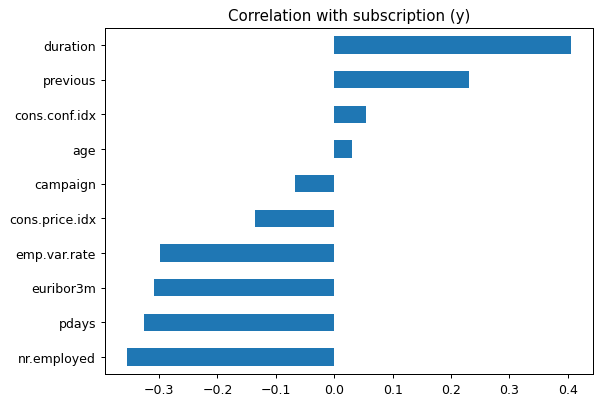

In [43]:
corr = df.corr(numeric_only=True)['y'].drop('y').sort_values()
corr.plot(kind='barh', figsize=(7, 5))
plt.title('Correlation with subscription (y)')
plt.show()

`duration` has the strongest correlation with `y` (0.41). The economic features `nr.employed`, `euribor3m` and `emp.var.rate` are about -0.3, which means that clients subscribe more when interest rates and employment variation are low. `pdays` is negative (-0.32) because the large value 999 stands for clients never contacted before. Correlation does not mean causation.


## Tasks


In this section, we will solve some tasks with the source bank dataset.


### Question 1


List of 10 clients with the largest number of contacts.


In [44]:
df.sort_values(by = "campaign", ascending = False).head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,age_band
4107,32,admin.,married,university.degree,unknown,unknown,unknown,telephone,may,mon,261,56,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0,26-35
18728,54,admin.,married,university.degree,unknown,yes,no,cellular,jul,thu,65,43,999,0,nonexistent,1.40,93.92,-42.70,4.97,5228.10,0,46-55
13447,32,technician,single,university.degree,no,yes,yes,telephone,jul,wed,16,43,999,0,nonexistent,1.40,93.92,-42.70,4.96,5228.10,0,26-35
4168,29,technician,married,professional.course,no,yes,no,telephone,may,mon,124,42,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0,26-35
5304,44,retired,married,basic.9y,no,yes,no,telephone,may,fri,147,42,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0,36-45
11033,38,blue-collar,married,basic.4y,no,yes,no,telephone,jun,wed,25,41,999,0,nonexistent,1.40,94.47,-41.80,4.96,5228.10,0,36-45
18754,36,admin.,single,university.degree,no,no,no,cellular,jul,thu,18,40,999,0,nonexistent,1.40,93.92,-42.70,4.97,5228.10,0,36-45
11769,56,self-employed,married,professional.course,no,no,yes,telephone,jun,fri,13,40,999,0,nonexistent,1.40,94.47,-41.80,4.96,5228.10,0,56-65
4114,52,entrepreneur,married,university.degree,no,no,no,telephone,may,mon,44,39,999,0,nonexistent,1.10,93.99,-36.40,4.86,5191.00,0,46-55
11593,43,technician,married,high.school,no,yes,no,telephone,jun,fri,17,37,999,0,nonexistent,1.40,94.47,-41.80,4.96,5228.10,0,36-45


The 10 most contacted clients were called from 37 to 56 times, and all of them refused (`y = 0`). So, calling the same client again and again does not work and only wastes the effort of the call center.

### Question 2


Determine the median age and the number of contacts for different levels of client education.


In [45]:
df.pivot_table(
    ["age", "campaign"],
    ["education"],
    aggfunc = ["median", "count"],
)


median           count         
                       age campaign    age campaign
education                                          
basic.4y             47.00     2.00   4176     4176
basic.6y             39.00     2.00   2292     2292
basic.9y             38.00     2.00   6045     6045
high.school          36.00     2.00   9515     9515
illiterate           48.00     2.00     18       18
professional.course  38.00     2.00   5243     5243
university.degree    36.00     2.00  12168    12168
unknown              43.00     2.00   1731     1731

The median number of contacts is 2 for every education level. The median age is the lowest for university degree and high school (36) and the highest for `basic.4y` (47), so clients with lower education are on average older. (`illiterate` has 48, but only 18 clients.)

### Question 3


Output box plot to analyze the client age distribution by their education level.


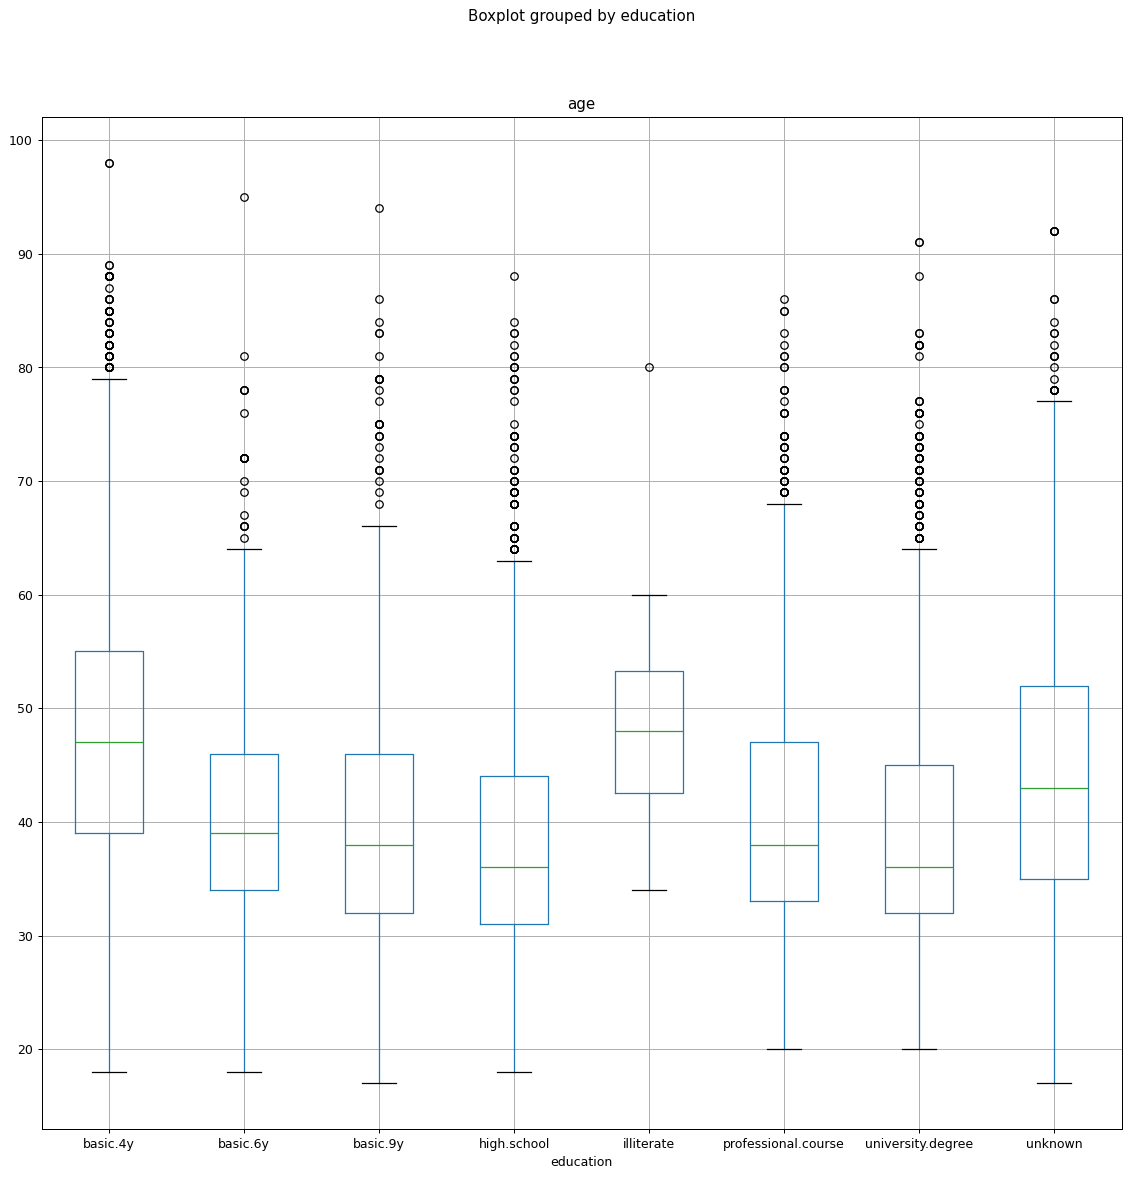

In [46]:
df.boxplot(column = "age",
  by = "education",
  figsize = (15, 15))
plt.show()

Most education levels have a median age between 36 and 39, while `basic.4y` (47), `unknown` (43) and `illiterate` (48) are older.

## Conclusions and recommendations

### Key findings
1. Only **11.3%** of the calls ended with a term deposit, so the campaign converts poorly. The target is imbalanced (4640 `yes` vs 36548 `no`).
2. **Who subscribes:** students (31.4%), retired clients (25.2%) and clients aged 65+ (46.8%) are the most responsive, while blue-collar and services workers are the least responsive (6.9% and 8.1%).
3. **How to reach them:** cellular contact converts almost 3 times better than telephone (14.7% vs 5.2%), in every job group.
4. **History matters:** after a successful previous campaign the rate is 65.1%, and 96.3% of the clients have never been contacted before, which is a large untapped base.
5. **Effort:** the rate falls as the number of contacts grows (13% for the first contact, about 5% for the tenth), and the 10 most contacted clients all refused.
6. **Timing and economy:** subscriptions were higher in periods of low interest rates (`euribor3m`) and in a few low-volume months (March, September, October, December), while May had a third of all calls with only 6.4% success.

### Recommendations for the next campaign
* Prioritise students, retired and senior clients, and clients with a successful previous campaign.
* Use cellular contact instead of telephone.
* Limit the repeated attempts to about 3 or 4 per client, because the results fall quickly after that.
* Test more calls outside May instead of concentrating a third of all calls in that month.
* Do not use `duration` to select clients (it is known only after the call), but use it as a quality signal for the call agents.

### Limitations 
* This is a descriptive analysis, so the results show relationships, not causes.
* High-rate segments (students, `65+`, March, September, October, December) are small, so they should be confirmed on more data.
* `unknown` values were kept as a separate category, and the 12 duplicated rows were left unchanged.